In [1]:
from pathlib import Path
from time import monotonic

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from custom_cnn import CustomCNN
from resnet import ResNet18


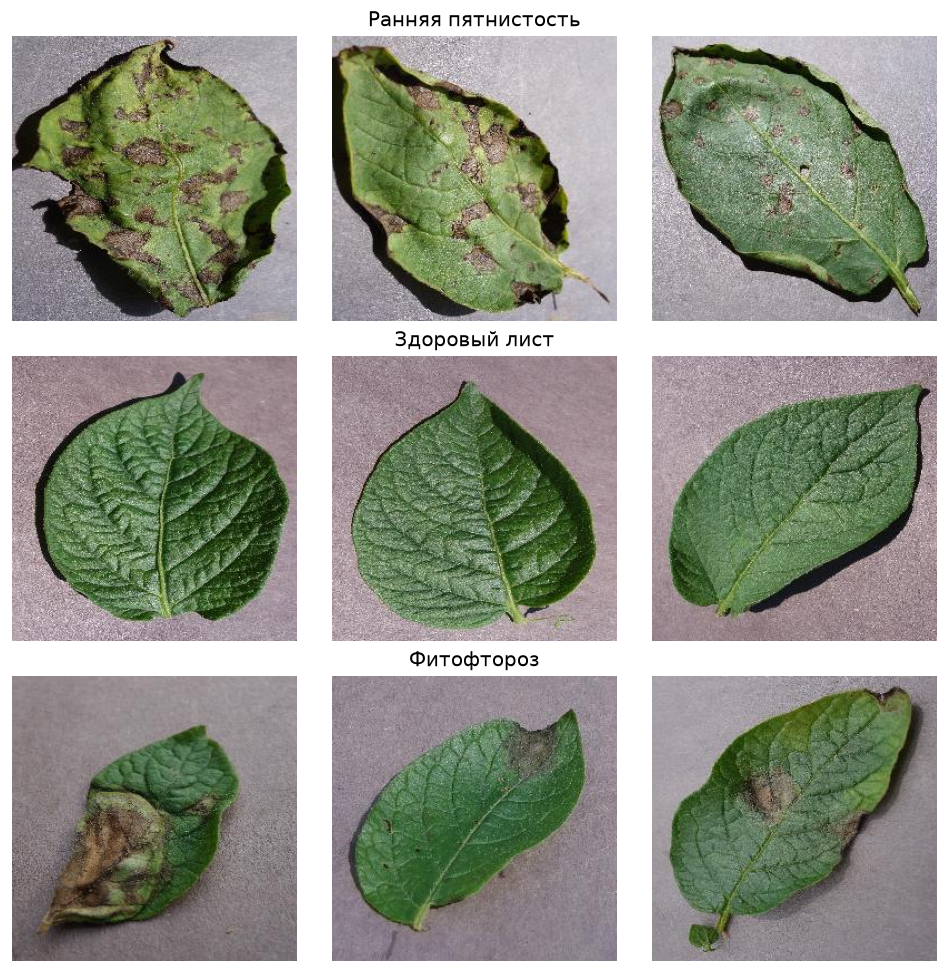

In [2]:
dataset_dir = Path("datasets") / "plantvillage-potato"
labels = {
    "Potato___Early_blight": "Ранняя пятнистость",
    "Potato___healthy": "Здоровый лист",
    "Potato___Late_blight": "Фитофтороз",
}

fig, axes = plt.subplots(3, 3, figsize=(8, 8), layout="constrained")

for row, (folder, label) in zip(axes, labels.items()):
    files = sorted((dataset_dir / folder).glob("*.jpg", case_sensitive=False))[:3]
    for ax, file in zip(row, files):
        ax.imshow(plt.imread(file))
        ax.axis("off")
    row[1].set_title(label)

plt.show()


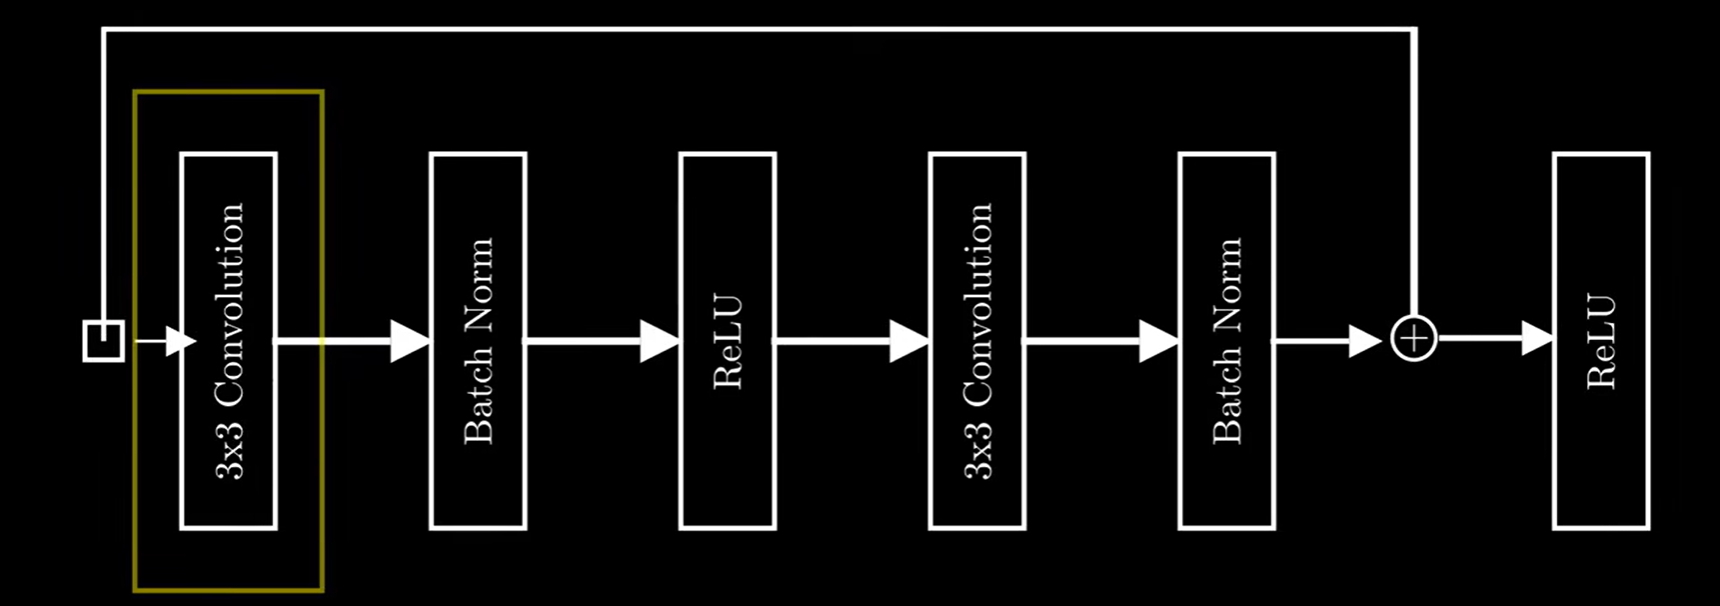

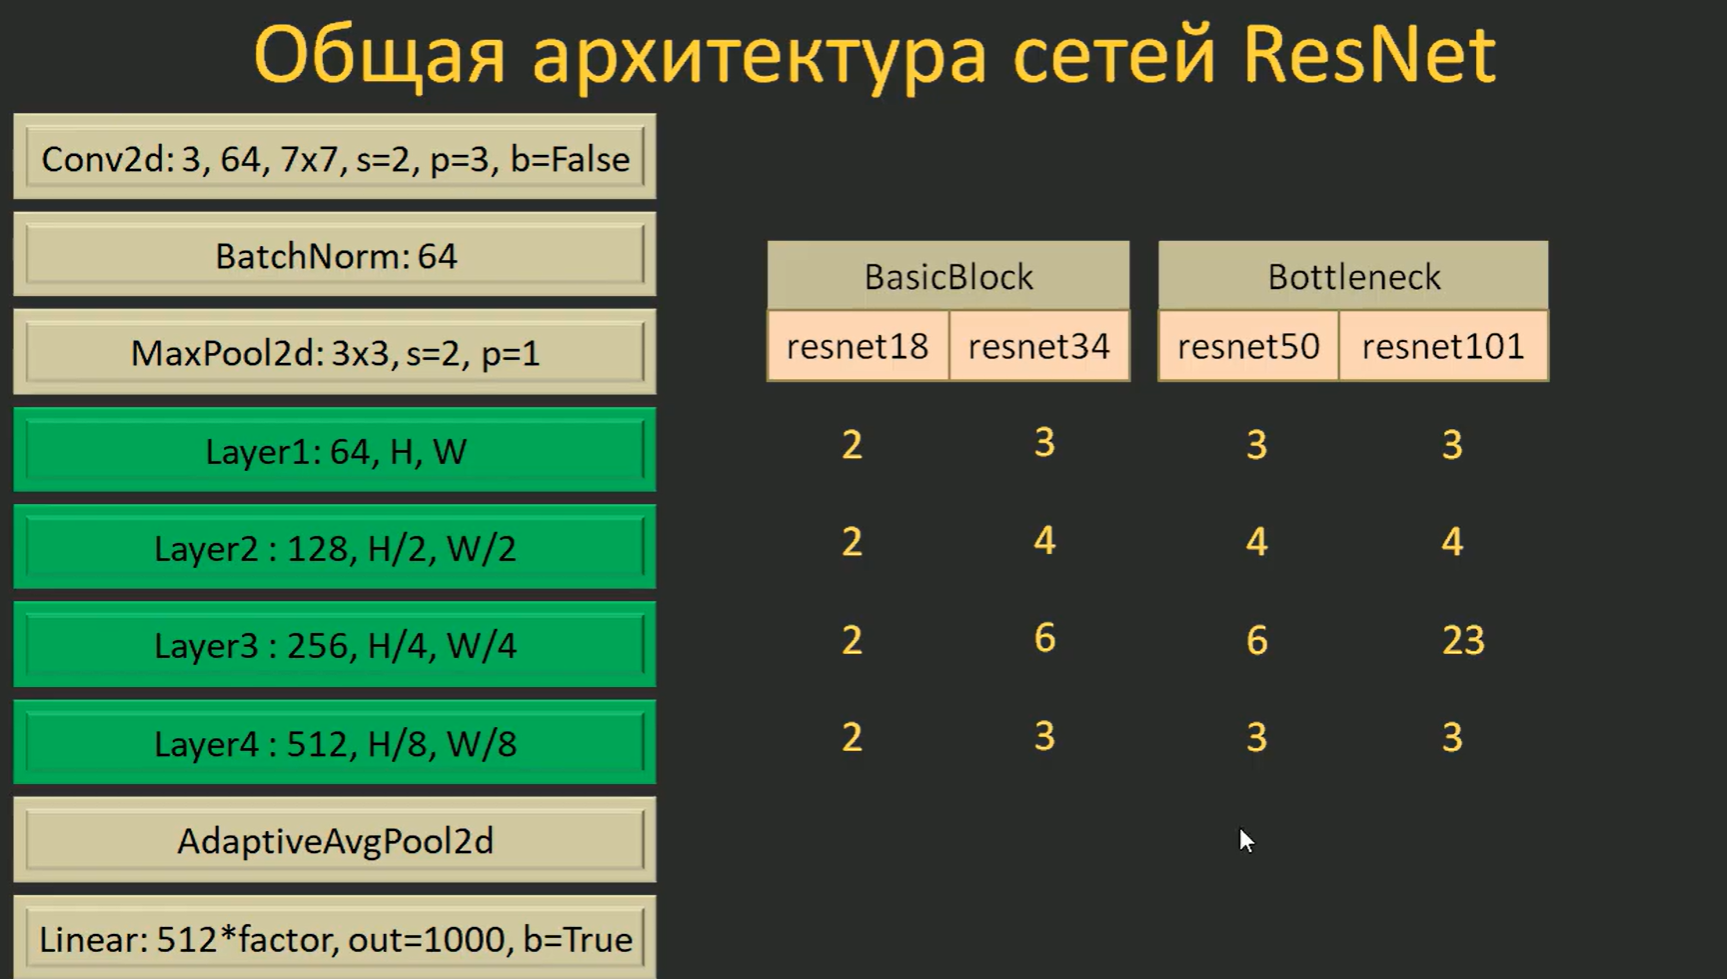

На схеме 1000 классов ImageNet. В нашей задаче линейный слой выдаёт три логита.


## 2. Обучение моделей
Обе модели используют одно разбиение. Веса классов одинаковы в обоих прогонах и учитывают дисбаланс. Тестовую выборку откладываем для итоговой оценки.

### Основная метрика

$$
R_{\mathrm{weighted}}(\alpha)=
\frac{R_{\text{альтернариоз}}+\alpha R_{\text{фитофтороз}}}{1+\alpha}.
$$

$R_c$ — доля правильно распознанных изображений среди всех изображений класса $c$. По умолчанию $\alpha=2$, поэтому recall фитофтороза влияет на итог вдвое сильнее. Здоровый класс в формулу не входит. Precision и число ложных тревог показываем отдельно. Функция обучения — взвешенная кросс-энтропия.


In [3]:
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

image_size = 64
batch_size = 32
train_ids, val_ids, test_ids = [], [], []
images, targets = [], []

# Делим каждый класс отдельно в пропорции 70/15/15
for class_id, folder in enumerate(labels):
    files = sorted((dataset_dir / folder).glob("*.jpg", case_sensitive=False))
    # randperm перемешивает индексы внутри класса
    indices = torch.randperm(len(files)) + len(images)
    train_end = int(0.70 * len(files))
    val_end = int(0.85 * len(files))
    train_ids.extend(indices[:train_end].tolist())
    val_ids.extend(indices[train_end:val_end].tolist())
    test_ids.extend(indices[val_end:].tolist())

    for file in files:
        with Image.open(file) as image:
            image = image.convert("RGB").resize((image_size, image_size))
            images.append(np.array(image))
        targets.append(class_id)

# permute переносит каналы из последней оси на вторую - N×H×W×C → N×C×H×W
images = torch.from_numpy(np.stack(images)).permute(0, 3, 1, 2)
targets = torch.tensor(targets)
num_classes = len(labels)

train_data = TensorDataset(images[train_ids], targets[train_ids])
val_data = TensorDataset(images[val_ids], targets[val_ids])
# DataLoader собирает батчи и перемешивает обучающие примеры перед каждой эпохой
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size)

# Повышаем вес редкого класса, чтобы ошибки на здоровых листьях не терялись
class_counts = torch.bincount(targets[train_ids])
class_weights = (len(train_ids) / (num_classes * class_counts)).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights, reduction="sum")

print(f"Устройство: {device} | Обучение: {len(train_ids)} | Валидация: {len(val_ids)} | Тест: {len(test_ids)}")


Устройство: cuda | Обучение: 1506 | Валидация: 323 | Тест: 323


In [4]:
def weighted_disease_recall(recall, alpha=2):
    # Индексы 0 и 2 - альтернариоз и фитофтороз в порядке labels
    return (recall[0] + alpha * recall[2]) / (1 + alpha)


def run_epoch(model, loader, optimizer=None, augment=False):
    training = optimizer is not None

    # В режиме оценки BatchNorm использует накопленную статистику
    model.train(training)
    total_loss, total_weight = 0.0, 0.0
    correct = torch.zeros(num_classes, dtype=torch.long, device=device)
    counts = torch.zeros_like(correct)

    # На валидации отключаем вычисление градиентов
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x = x.to(device).float() / 255
            y = y.to(device)

            # Выбираем случайные изображения в батче и отражаем их по ширине
            if training and augment:
                flip = torch.rand(len(x), device=device) < 0.5
                x[flip] = x[flip].flip(-1)

                # rot90 поворачивает квадратные изображения на 0, 90, 180 или 270 градусов
                turns = torch.randint(0, 4, (len(x),), device=device)
                for k in (1, 2, 3):
                    mask = turns == k
                    x[mask] = x[mask].rot90(k, dims=(-2, -1))

                # Меняем яркость каждого изображения в пределах 10% и сохраняем диапазон [0, 1]
                brightness = 0.9 + 0.2 * torch.rand(len(x), 1, 1, 1, device=device)
                x = (x * brightness).clamp(0, 1)

            # CrossEntropyLoss принимает логиты и индексы правильных классов
            logits = model(x)
            loss = criterion(logits, y)
            weight = class_weights[y].sum()

            if training:
                # Сбрасываем градиенты, считаем новые и обновляем веса
                optimizer.zero_grad()
                (loss / weight).backward()
                optimizer.step()

            # Суммируем взвешенную ошибку по батчам для среднего за эпоху
            total_loss += loss.item()
            total_weight += weight.item()

            # argmax выбирает класс с наибольшим логитом
            matches = logits.argmax(dim=1) == y

            # bincount считает число примеров и верных ответов каждого класса
            counts += torch.bincount(y, minlength=num_classes)
            correct += torch.bincount(y[matches], minlength=num_classes)

    # Recall каждого класса - доля верных ответов среди его примеров
    recall = correct / counts
    return total_loss / total_weight, recall.tolist()


In [5]:
epochs = 80
alpha = 2  # - относительная важность фитофтороза
checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(exist_ok=True)


def fit(model_class, augment=False, alpha=2):
    # Повторно задаём seed для одинаковых начальных весов в двух прогонах
    torch.manual_seed(42)
    model = model_class(num_classes=num_classes).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    history = []
    best_recall = -1.0
    name = model_class.__name__
    suffix = "_augmented" if augment else "_baseline"
    checkpoint = checkpoint_dir / f"{name}{suffix}.pt"

    for epoch in range(1, epochs + 1):
        train_loss, train_by_class = run_epoch(model, train_loader, optimizer, augment=augment)
        val_loss, valid_by_class = run_epoch(model, val_loader)
        train_recall = weighted_disease_recall(train_by_class, alpha)
        val_recall = weighted_disease_recall(valid_by_class, alpha)
        history.append((train_loss, train_recall, val_loss, val_recall))

        # При равном recall сохраняем более раннюю эпоху.
        if val_recall > best_recall:
            best_recall = val_recall
            torch.save({"weights": model.state_dict(), "epoch": epoch}, checkpoint)
        print(
            f"{name} | {epoch:2d} | train loss {train_loss:.3f}, weighted disease recall {train_recall:.1%}"
            f" | valid loss {val_loss:.3f}, weighted disease recall {val_recall:.1%}",
            flush=True,
        )

    return history


In [6]:
def plot_history(history):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
    for row, (name, rows) in zip(axes, history.items()):
        train_loss, train_recall, val_loss, val_recall = zip(*rows)
        steps = range(1, len(rows) + 1)

        row[0].plot(steps, train_loss, label="train")
        row[0].plot(steps, val_loss, "--", label="valid")
        row[0].set(title=name, xlabel="Epoch", ylabel="Loss")
        row[0].legend()

        row[1].plot(steps, train_recall, label="train")
        row[1].plot(steps, val_recall, "--", label="valid")
        row[1].set(title=name, xlabel="Epoch", ylabel="Weighted disease recall", ylim=(0, 1))
        row[1].legend()

    plt.show()


### Базовый прогон
Обучаем обе модели 80 эпох. По графикам смотрим, как меняются ошибка и взвешенный recall болезней на обучении и валидации.

CustomCNN |  1 | train loss 1.096, weighted disease recall 32.6% | valid loss 1.085, weighted disease recall 33.3%
CustomCNN |  2 | train loss 1.082, weighted disease recall 41.3% | valid loss 1.072, weighted disease recall 33.3%
CustomCNN |  3 | train loss 1.045, weighted disease recall 62.4% | valid loss 0.992, weighted disease recall 70.0%
CustomCNN |  4 | train loss 0.930, weighted disease recall 82.6% | valid loss 0.856, weighted disease recall 93.1%
CustomCNN |  5 | train loss 0.814, weighted disease recall 86.9% | valid loss 0.763, weighted disease recall 73.3%
CustomCNN |  6 | train loss 0.740, weighted disease recall 80.3% | valid loss 0.891, weighted disease recall 86.0%
CustomCNN |  7 | train loss 0.723, weighted disease recall 82.0% | valid loss 1.047, weighted disease recall 43.1%
CustomCNN |  8 | train loss 0.728, weighted disease recall 78.9% | valid loss 0.693, weighted disease recall 74.9%
CustomCNN |  9 | train loss 0.645, weighted disease recall 83.6% | valid loss 0.

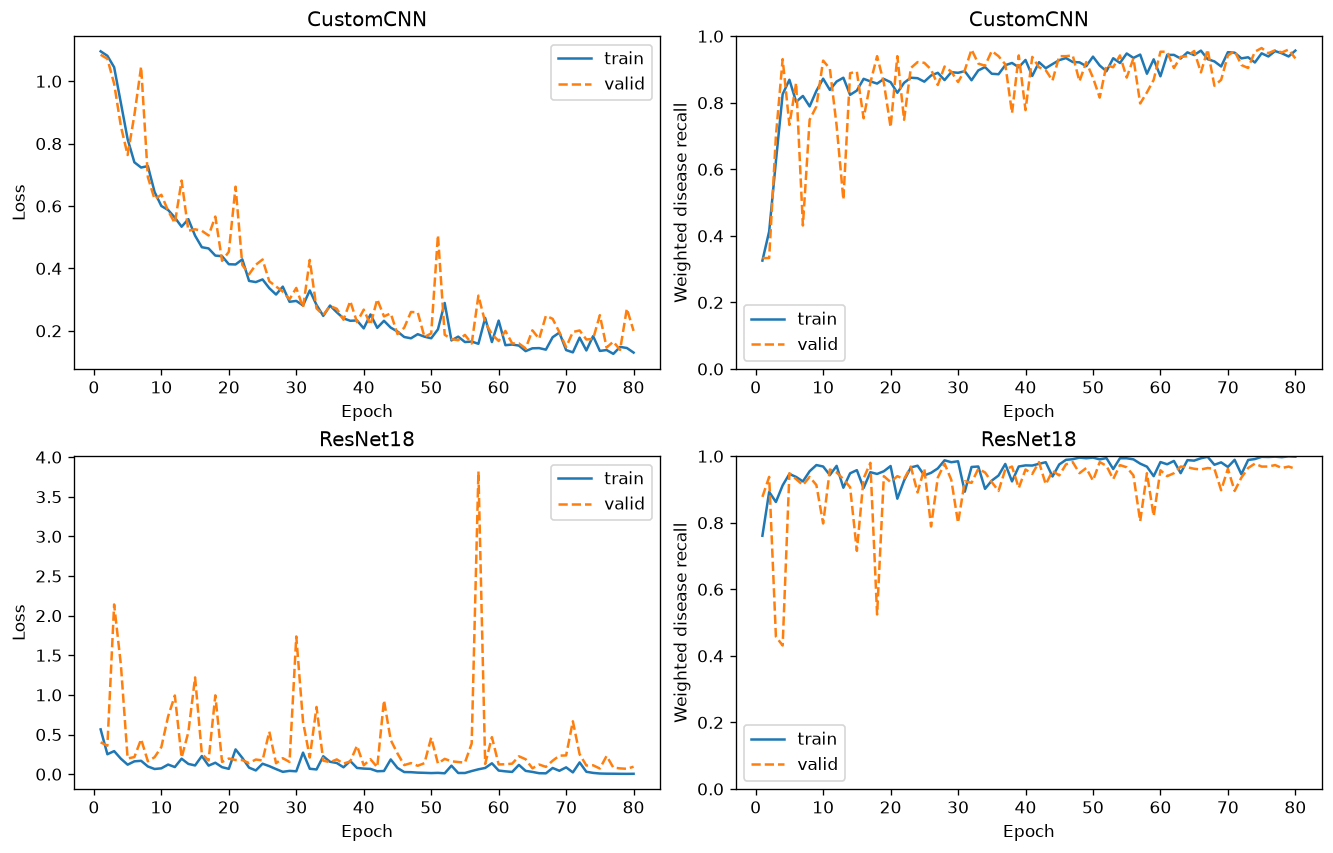

In [7]:
start = monotonic()
models = (CustomCNN, ResNet18)

baseline_history = {model.__name__: fit(model, alpha=alpha) for model in models}
plot_history(baseline_history)


На итоговом графике сравниваем сохранённые веса лучших эпох каждого прогона.

### Борьба с переобучением
На train случайно отражаем изображения по горизонтали с вероятностью 0,5, поворачиваем на 0°, 90°, 180° или 270° и меняем яркость множителем от 0,9 до 1,1. Используем те же начальные веса и разбиение, обучаем обе модели 80 эпох. На valid аугментации не применяем.


CustomCNN |  1 | train loss 1.096, weighted disease recall 32.6% | valid loss 1.085, weighted disease recall 33.3%
CustomCNN |  2 | train loss 1.084, weighted disease recall 39.9% | valid loss 1.075, weighted disease recall 33.3%
CustomCNN |  3 | train loss 1.055, weighted disease recall 60.4% | valid loss 1.007, weighted disease recall 53.3%
CustomCNN |  4 | train loss 0.943, weighted disease recall 80.4% | valid loss 0.877, weighted disease recall 93.6%
CustomCNN |  5 | train loss 0.847, weighted disease recall 82.2% | valid loss 0.764, weighted disease recall 75.1%
CustomCNN |  6 | train loss 0.766, weighted disease recall 78.5% | valid loss 0.875, weighted disease recall 86.4%
CustomCNN |  7 | train loss 0.755, weighted disease recall 77.5% | valid loss 0.914, weighted disease recall 48.7%
CustomCNN |  8 | train loss 0.752, weighted disease recall 76.5% | valid loss 0.689, weighted disease recall 83.8%
CustomCNN |  9 | train loss 0.662, weighted disease recall 82.7% | valid loss 0.

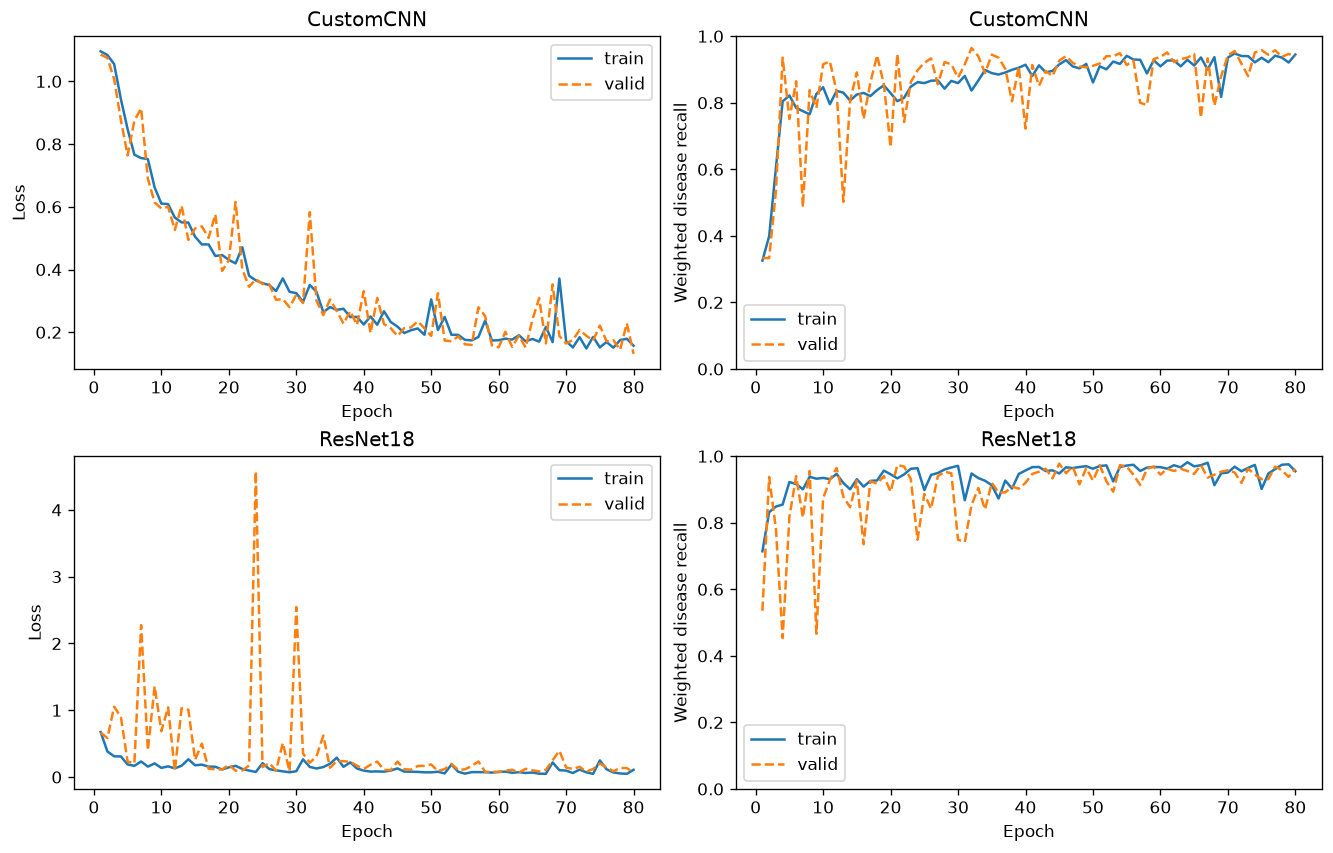

In [8]:
start = monotonic()
augmented_history = {model.__name__: fit(model, augment=True, alpha=alpha) for model in models}
plot_history(augmented_history)
print(f"Прогон с аугментацией: {monotonic() - start:.0f} с")


### Сравнение лучших эпох на валидации

Выбираем лучшую эпоху каждого прогона по взвешенному recall болезней. При равенстве сохраняем более раннюю эпоху.

### Сравнение моделей на валидации

Основная метрика — взвешенный recall болезней. Фитофтороз имеет вес 2, ранняя пятнистость — вес 1.

- **Recall диагноза** — доля правильно распознанных листьев среди всех листьев с этой болезнью.
- **Precision диагноза** — доля верных диагнозов среди всех предсказаний этого диагноза.
- **Ложные тревоги** — доля здоровых листьев, которым модель поставила любой из двух диагнозов. На столбцах указано число таких листьев из общего числа здоровых.

При обучении сохраняем эпоху с максимальным взвешенным recall на валидации. При равенстве выбираем более раннюю эпоху.


Модель | Прогон | Лучшая эпоха | Взвешенный recall (α=2)
CustomCNN | Без аугментаций | 75 | 96.44%
CustomCNN | С аугментациями | 32 | 96.44%
ResNet18 | Без аугментаций | 42 | 98.22%
ResNet18 | С аугментациями | 45 | 97.78%


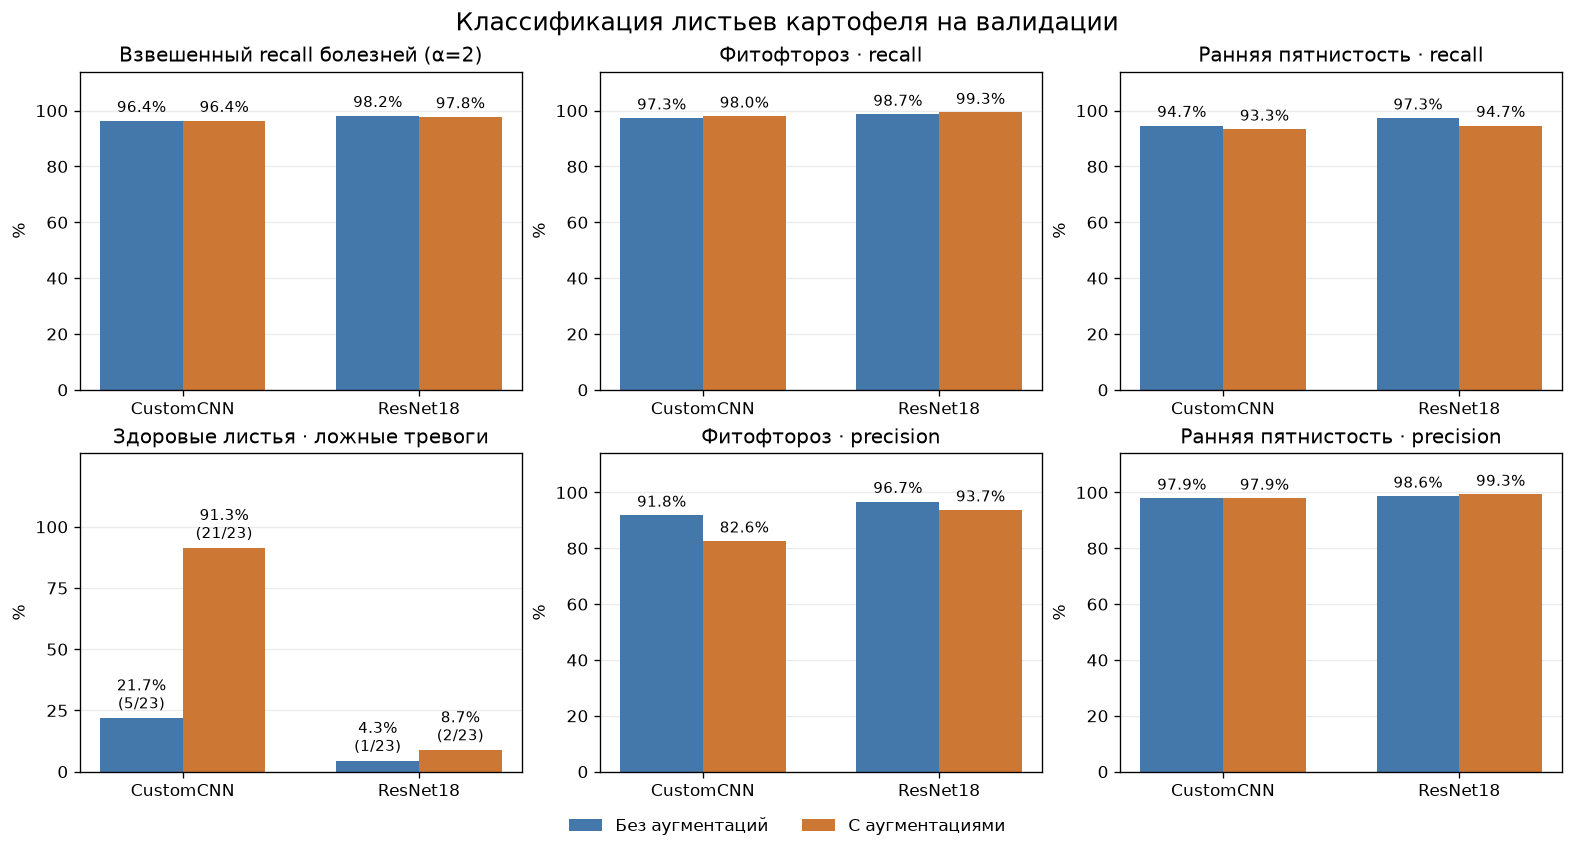

In [9]:
print(f"Модель | Прогон | Лучшая эпоха | Взвешенный recall (α={alpha})")
results = {}
runs = {"baseline": "Без аугментаций", "augmented": "С аугментациями"}

for model_class in models:
    for run, run_label in runs.items():
        model = model_class(num_classes=num_classes).to(device)
        checkpoint = checkpoint_dir / f"{model_class.__name__}_{run}.pt"
        saved = torch.load(checkpoint, map_location=device, weights_only=True)
        model.load_state_dict(saved["weights"])
        model.eval()

        # Строка матрицы — истинный класс, столбец — предсказанный.
        matrix = torch.zeros((num_classes, num_classes), dtype=torch.long, device=device)
        with torch.inference_mode():
            for x, y in val_loader:
                predicted = model(x.to(device).float() / 255).argmax(dim=1)
                pairs = y.to(device) * num_classes + predicted
                matrix += torch.bincount(pairs, minlength=num_classes ** 2).reshape_as(matrix)

        correct = matrix.diag()
        recall = (correct / matrix.sum(dim=1)).tolist()
        precision = (correct / matrix.sum(dim=0).clamp_min(1)).tolist()
        weighted_recall = weighted_disease_recall(recall, alpha)
        healthy = matrix[1].sum().item()
        false_alarms = healthy - correct[1].item()

        results[model_class.__name__, run] = (
            weighted_recall, recall[2], recall[0],
            false_alarms / healthy, precision[2], precision[0],
        ), f"{false_alarms}/{healthy}"
        best_epoch = saved["epoch"]
        print(f"{model_class.__name__} | {run_label} | {best_epoch} | {weighted_recall:.2%}")

fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout="constrained")
fig.suptitle("Классификация листьев картофеля на валидации", fontsize=15)
titles = [
    f"Взвешенный recall болезней (α={alpha})",
    "Фитофтороз · recall",
    "Ранняя пятнистость · recall",
    "Здоровые листья · ложные тревоги",
    "Фитофтороз · precision",
    "Ранняя пятнистость · precision",
]
names = [model_class.__name__ for model_class in models]
positions = np.arange(len(names))
width = 0.35

for metric, (ax, title) in enumerate(zip(axes.flat, titles)):
    for (run, run_label), offset, color in zip(runs.items(), (-width / 2, width / 2), ("#4477AA", "#CC7733")):
        rows = [results[name, run] for name in names]
        values = [metrics[metric] * 100 for metrics, _ in rows]
        bars = ax.bar(positions + offset, values, width, color=color, label=run_label)
        if metric == 3:
            annotations = [f"{value:.1f}%\n({count})" for value, (_, count) in zip(values, rows)]
        else:
            annotations = [f"{value:.1f}%" for value in values]
        ax.bar_label(bars, labels=annotations, padding=3, fontsize=9)

    ax.set_xticks(positions, names)
    ax.set(title=title, ylim=(0, 114), yticks=range(0, 101, 20), ylabel="%")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

# У ложных тревог отдельный масштаб, чтобы были видны малые доли.
max_false_alarms = max(metrics[3] * 100 for metrics, _ in results.values())
alarm_limit = min(100, max(20, 10 * (int(max_false_alarms / 10) + 1)))
axes[1, 0].set(ylim=(0, alarm_limit * 1.3), yticks=range(0, alarm_limit + 1, alarm_limit // 4))
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="outside lower center", ncols=2, frameon=False)
plt.show()


Вывод: 

1) если смотреть на resnet, то взвешанный recal не изменился. Но конкретно по своя Фитофтороз recall повысился, а recal по ранней пятнистости уменьшился. Для нашей задачи это лучше, тк Фитофтороз опаснее для нашей картошки, чем рання пятнистость


2) своя cnn по взвешанному recall слабо отличается от resnet. Хотя слоев 3 и 18 соотвественно. и скорость в 4 раза быстрее у своего cnn. Однако, ложные срабатывания сильно уменьшились у resnet. Можно сказать, что если очень важна скорост работы, стоит брать нашу реализация cnn. Если важно чуть лучше угадывать болезни и в 10 раз реже ложно срабатывать на здоровых листьях, то берем resnet18

### 2.1. Валидация модели классификации



ResNet18 | С аугментациями | эпоха 45 | тест: 323 листа
Взвешенный recall болезней (α=2) — 97.33%


| Истинный класс | Изображений в тесте | Recall | Precision |
| --- | ---: | ---: | ---: |
| Ранняя пятнистость | 150 | 96.00% | 98.63% |
| Здоровый лист | 23 | 95.65% | 95.65% |
| Фитофтороз | 150 | 98.00% | 95.45% |

Ложные тревоги на здоровых листьях — 1/23 (4.35%)


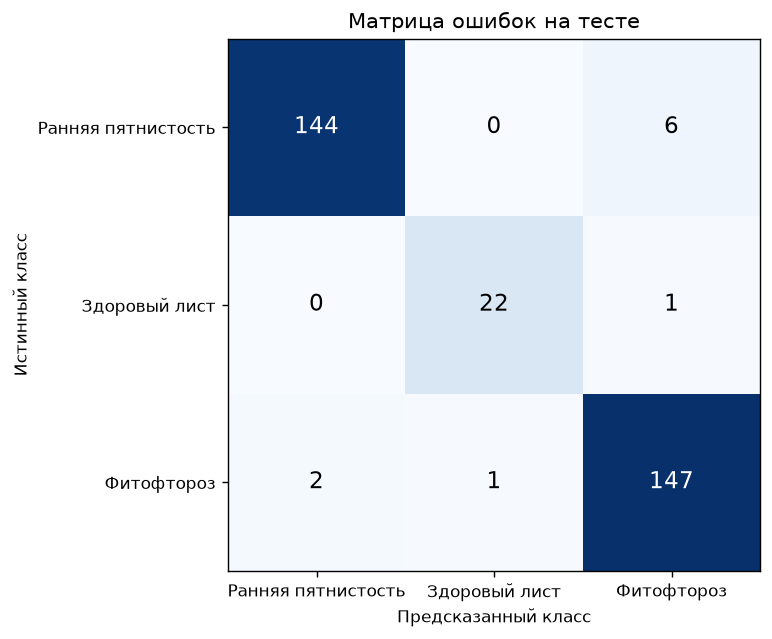

In [10]:
# Основная модель для следующих пунктов лабораторной.
best_name, best_run = "ResNet18", "augmented"
best_model_class = ResNet18
checkpoint = checkpoint_dir / f"{best_name}_{best_run}.pt"
saved = torch.load(checkpoint, map_location=device, weights_only=True)
model = best_model_class(num_classes=num_classes).to(device)
model.load_state_dict(saved["weights"])
model.eval()

test_data = TensorDataset(images[test_ids], targets[test_ids])
test_loader = DataLoader(test_data, batch_size=batch_size)
test_matrix = torch.zeros((num_classes, num_classes), dtype=torch.long, device=device)

with torch.inference_mode():
    for x, y in test_loader:
        predicted = model(x.to(device).float() / 255).argmax(dim=1)
        # Кодируем пару (истинный класс, предсказанный класс) одним индексом.
        pairs = y.to(device) * num_classes + predicted
        test_matrix += torch.bincount(pairs, minlength=num_classes ** 2).reshape_as(test_matrix)

correct = test_matrix.diag()
recall = (correct / test_matrix.sum(dim=1)).tolist()
precision = (correct / test_matrix.sum(dim=0).clamp_min(1)).tolist()
healthy = test_matrix[1].sum().item()
false_alarms = healthy - correct[1].item()

print(f"{best_name} | {runs[best_run]} | эпоха {saved['epoch']} | тест: {len(test_data)} листа")
print(f"Взвешенный recall болезней (α={alpha}) — {weighted_disease_recall(recall, alpha):.2%}")
from IPython.display import Markdown, display

class_names = list(labels.values())
metrics_table = [
    "| Истинный класс | Изображений в тесте | Recall | Precision |",
    "| --- | ---: | ---: | ---: |",
]
test_counts = test_matrix.sum(dim=1).tolist()
for name, count, r, p in zip(class_names, test_counts, recall, precision):
    metrics_table.append(f"| {name} | {count} | {r:.2%} | {p:.2%} |")
display(Markdown("\n".join(metrics_table)))

print(f"Ложные тревоги на здоровых листьях — {false_alarms}/{healthy} ({false_alarms / healthy:.2%})")

# Строки соответствуют истинным классам, столбцы — предсказаниям.
counts = test_matrix.cpu().numpy()
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
ax.imshow(counts, cmap="Blues", vmin=0)
ax.set_xticks(range(num_classes), class_names)
ax.set_yticks(range(num_classes), class_names)
ax.set(xlabel="Предсказанный класс", ylabel="Истинный класс", title="Матрица ошибок на тесте")
for row in range(num_classes):
    for column in range(num_classes):
        count = counts[row, column]
        color = "white" if count > counts.max() / 2 else "black"
        ax.text(column, row, str(count), ha="center", va="center", color=color, fontsize=13)
plt.show()
